<a href="https://colab.research.google.com/github/Hadeel-93/Final-Project/blob/main/Project%2B%2B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cell 1 — Install Required Packages

!pip -q install wfdb

In [ ]:
# Cell 2 — Import Libraries

import os
import ast
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import wfdb

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Cell 3 — Set Random Seeds and Device

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [ ]:
# Cell 4 — Define PTB-XL Source

PTBXL_BASE_URL = "https://physionet.org/files/ptb-xl/1.0.3"

DATABASE_URL = f"{PTBXL_BASE_URL}/ptbxl_database.csv"

print("PTB-XL source:")
print(DATABASE_URL)

PTB-XL source:
https://physionet.org/files/ptb-xl/1.0.3/ptbxl_database.csv


In [ ]:
# Cell 5 — Load PTB-XL Metadata

df = pd.read_csv(DATABASE_URL, index_col="ecg_id")

print("Number of ECG recordings:", len(df))
print("Number of columns:", len(df.columns))

display(df.head())

Number of ECG recordings: 21799
Number of columns: 27


,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


In [ ]:
# Cell 6 — Inspect Diagnostic Labels

print(df["scp_codes"].iloc[0])

print("\nExample diagnostic statements:")

for i in range(5):
    print(f"ECG {df.index[i]}:", df["scp_codes"].iloc[i])

{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}

Example diagnostic statements:
ECG 1: {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
ECG 2: {'NORM': 80.0, 'SBRAD': 0.0}
ECG 3: {'NORM': 100.0, 'SR': 0.0}
ECG 4: {'NORM': 100.0, 'SR': 0.0}
ECG 5: {'NORM': 100.0, 'SR': 0.0}


In [ ]:
# Cell 7 — Create Binary Normal/Abnormal Labels

def create_binary_label(scp_codes):
    codes = ast.literal_eval(scp_codes)

    # Normal ECG
    if "NORM" in codes:
        # If NORM is present by itself, classify as normal
        other_diagnostic_codes = [
            code for code in codes.keys()
            if code != "NORM"
        ]

        if len(other_diagnostic_codes) == 0:
            return 0

    # Otherwise abnormal
    return 1


df["label"] = df["scp_codes"].apply(create_binary_label)

df["label_name"] = df["label"].map({
    0: "Normal",
    1: "Abnormal"
})

print(df["label_name"].value_counts())

label_name
Abnormal    21609
Normal        190
Name: count, dtype: int64


In [ ]:
# Cell 8 — Check Class Distribution

class_counts = df["label"].value_counts().sort_index()

class_percentages = (
    df["label"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

distribution = pd.DataFrame({
    "Class": ["Normal", "Abnormal"],
    "Count": class_counts.values,
    "Percentage": class_percentages.values
})

display(distribution)

,Class,Count,Percentage
0,Normal,190,0.8716
1,Abnormal,21609,99.1284


In [ ]:
# Cell 9 — Create Train/Validation/Test Splits

train_df = df[df["strat_fold"].isin(range(1, 9))].copy()

val_df = df[df["strat_fold"] == 9].copy()

test_df = df[df["strat_fold"] == 10].copy()

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

Training samples: 17418
Validation samples: 2183
Test samples: 2198


In [ ]:
# Cell 10 — Check Class Distribution for Each Split

def show_distribution(data, name):
    counts = data["label"].value_counts().sort_index()
    percentages = data["label"].value_counts(normalize=True).sort_index() * 100

    print(f"\n{name}")
    print("-" * 40)
    print(f"Normal   : {counts.get(0, 0)} ({percentages.get(0, 0):.2f}%)")
    print(f"Abnormal : {counts.get(1, 0)} ({percentages.get(1, 0):.2f}%)")


show_distribution(train_df, "Training Set")
show_distribution(val_df, "Validation Set")
show_distribution(test_df, "Test Set")


Training Set
----------------------------------------
Normal   : 150 (0.86%)
Abnormal : 17268 (99.14%)

Validation Set
----------------------------------------
Normal   : 11 (0.50%)
Abnormal : 2172 (99.50%)

Test Set
----------------------------------------
Normal   : 29 (1.32%)
Abnormal : 2169 (98.68%)


In [ ]:
# Cell 11 — Define ECG Waveform Reader with Retries

def load_ecg(record_path, max_retries=5, backoff_factor=1.5):
    """
    Load one PTB-XL ECG recording from PhysioNet using wfdb with retries for network robustness.

    Returns:
        ECG array with shape (12, 1000)
    """
    record_dir, record_name = os.path.split(record_path)
    pn_dir = f"ptb-xl/1.0.3/{record_dir}"

    for attempt in range(max_retries):
        try:
            signal, fields = wfdb.rdsamp(record_name, pn_dir=pn_dir)
            signal = signal.T
            return signal.astype(np.float32)
        except Exception as e:
            if attempt == max_retries - 1:
                raise e
            sleep_time = backoff_factor ** attempt
            print(f"Network error on {record_name} (Attempt {attempt+1}/{max_retries}). Retrying in {sleep_time:.2f}s... Error: {e}")
            time.sleep(sleep_time)

In [ ]:
# Cell 12 — Test Direct ECG Access

sample_record = train_df.iloc[0]["filename_lr"]

print("Testing record:")
print(sample_record)

sample_ecg = load_ecg(sample_record)

print("\nECG shape:", sample_ecg.shape)
print("Data type:", sample_ecg.dtype)

Testing record:
records100/00000/00001_lr

ECG shape: (12, 1000)
Data type: float32


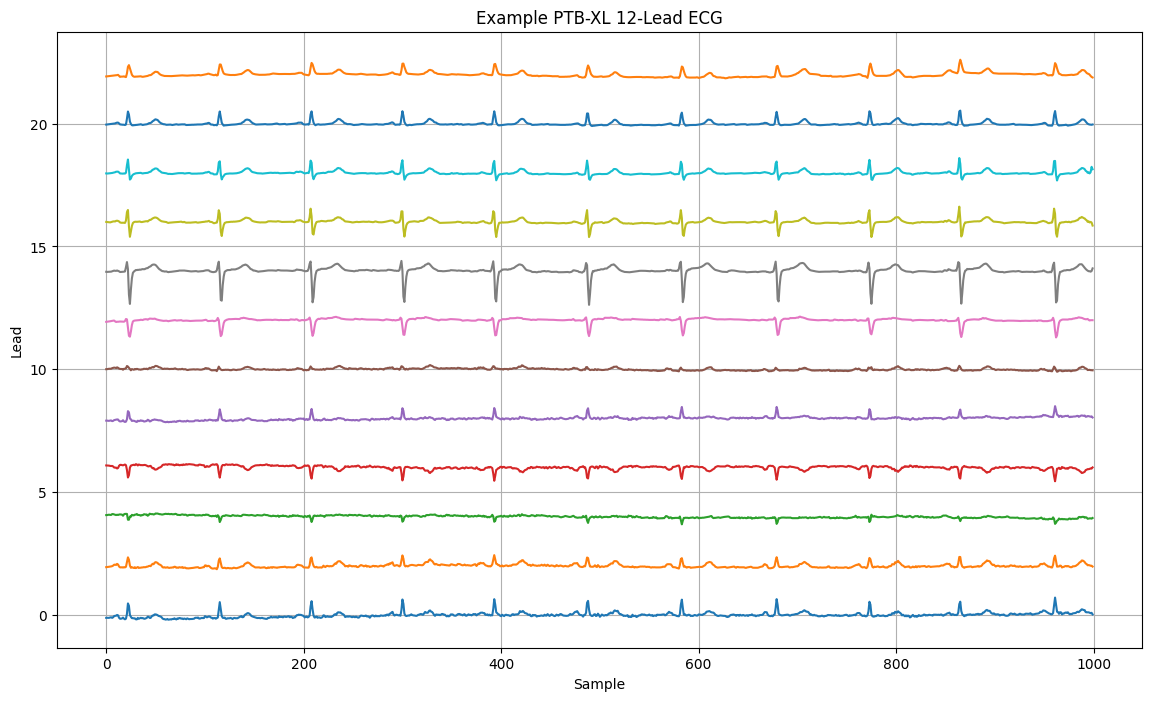

In [ ]:
# Cell 13 — Visualize Example ECG

plt.figure(figsize=(14, 8))

for lead in range(12):
    plt.plot(sample_ecg[lead] + lead * 2)

plt.title("Example PTB-XL 12-Lead ECG")
plt.xlabel("Sample")
plt.ylabel("Lead")
plt.grid(True)

plt.show()

In [ ]:
# Cell 14 — ECG Standardization

def normalize_ecg(ecg):
    """
    Standardize each ECG lead independently.
    Input shape: (12, 1000)
    Output shape: (12, 1000)
    """

    mean = np.mean(ecg, axis=1, keepdims=True)
    std = np.std(ecg, axis=1, keepdims=True)

    std = np.where(std < 1e-8, 1.0, std)

    ecg_normalized = (ecg - mean) / std

    return ecg_normalized.astype(np.float32)

In [ ]:
# Cell 15 — Test ECG Normalization

normalized_sample = normalize_ecg(sample_ecg)

print("Original mean:", np.mean(sample_ecg))
print("Original std :", np.std(sample_ecg))

print("\nNormalized mean:", np.mean(normalized_sample))
print("Normalized std :", np.std(normalized_sample))

Original mean: 0.00010475
Original std : 0.10763455

Normalized mean: 4.5776368e-08
Normalized std : 1.0


In [ ]:
# Cell 16 — Create Local PTB-XL Data Directory

import os

LOCAL_DATA_DIR = "/content/ptbxl_100hz"

os.makedirs(LOCAL_DATA_DIR, exist_ok=True)

print("Local data directory:")
print(LOCAL_DATA_DIR)

Local data directory:
/content/ptbxl_100hz


In [ ]:
# Cell 17 — Download PTB-XL ECG Record

import requests
import time

def download_file(url, local_path, max_retries=5):

    if os.path.exists(local_path):
        return True

    for attempt in range(max_retries):

        try:

            response = requests.get(
                url,
                timeout=60
            )

            if response.status_code == 200:

                with open(local_path, "wb") as f:
                    f.write(response.content)

                return True

            else:
                print(
                    f"Attempt {attempt + 1}/{max_retries}: "
                    f"HTTP {response.status_code}"
                )

        except Exception as e:

            print(
                f"Attempt {attempt + 1}/{max_retries}: {e}"
            )

        time.sleep(2 ** attempt)

    return False

In [ ]:
# Cell 18 — Download ECG Header and Signal Files

def prepare_ecg(record_path):

    record_name = os.path.basename(record_path)

    # Example:
    # records100/00000/00067_lr
    #
    # becomes:
    # 00067_lr.hea
    # 00067_lr.dat

    relative_dir = os.path.dirname(record_path)

    local_dir = os.path.join(
        LOCAL_DATA_DIR,
        relative_dir
    )

    os.makedirs(local_dir, exist_ok=True)

    hea_url = (
        f"{PTBXL_BASE_URL}/{record_path}.hea"
    )

    dat_url = (
        f"{PTBXL_BASE_URL}/{record_path}.dat"
    )

    hea_local = os.path.join(
        LOCAL_DATA_DIR,
        f"{record_path}.hea"
    )

    dat_local = os.path.join(
        LOCAL_DATA_DIR,
        f"{record_path}.dat"
    )

    hea_success = download_file(
        hea_url,
        hea_local
    )

    dat_success = download_file(
        dat_url,
        dat_local
    )

    return hea_success and dat_success

In [ ]:
# Cell 19 — Test Local Download

test_record = train_df.iloc[0]["filename_lr"]

print("Testing record:")
print(test_record)

success = prepare_ecg(test_record)

print("\nDownload successful:", success)

Testing record:
records100/00000/00001_lr

Download successful: True


In [ ]:
# Cell 20 — Read Local ECG

def load_local_ecg(record_path):

    local_record_path = os.path.join(
        LOCAL_DATA_DIR,
        record_path
    )

    signal, fields = wfdb.rdsamp(
        local_record_path
    )

    # Convert:
    # (1000, 12)
    #
    # to:
    # (12, 1000)

    signal = signal.T

    return signal.astype(np.float32)

In [ ]:
# Cell 21 — Verify Local ECG

local_sample = load_local_ecg(test_record)

print("Local ECG shape:", local_sample.shape)
print("Data type:", local_sample.dtype)

Local ECG shape: (12, 1000)
Data type: float32


### Alternate Step: Fast Archive Download

Instead of downloading 17,418 records individually, we can download the full PTB-XL archive once and extract it locally. This bypasses the slow sequential network requests.

In [64]:
import os
import shutil

LOCAL_DATA_DIR = "/content/ptbxl_100hz"
parent_extracted = "/content/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3"

# FORCE CLEAN: Delete existing incomplete data folders to trigger a fresh extraction
if os.path.exists(LOCAL_DATA_DIR):
    print(f"Cleaning incomplete data directory: {LOCAL_DATA_DIR}")
    shutil.rmtree(LOCAL_DATA_DIR)
os.makedirs(LOCAL_DATA_DIR, exist_ok=True)

if os.path.exists(parent_extracted):
    shutil.rmtree(parent_extracted)

# Ensure the zip archive exists
if not os.path.exists("/content/ptb-xl.zip"):
    print("Downloading PTB-XL zip archive (1.7 GB). Please wait, do not interrupt...")
    !wget -q --show-progress -O /content/ptb-xl.zip https://physionet.org/static/published-projects/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip
else:
    print("Using existing local zip archive.")

print("Extracting dataset archive completely...")
!unzip -q -o /content/ptb-xl.zip -d /content/

# Relocate folders
if os.path.exists(parent_extracted):
    print("Relocating dataset files...")
    for item in os.listdir(parent_extracted):
        src = os.path.join(parent_extracted, item)
        dst = os.path.join(LOCAL_DATA_DIR, item)
        shutil.move(src, dst)
    shutil.rmtree(parent_extracted)

# Clean up the zip file
if os.path.exists("/content/ptb-xl.zip"):
    os.remove("/content/ptb-xl.zip")

print("\n--- Verification ---")
print("Local directory contents:", os.listdir(LOCAL_DATA_DIR))
sample_file = os.path.join(LOCAL_DATA_DIR, "records100/11000/11294_lr.hea")
print(f"Target file exists ({sample_file}): {os.path.exists(sample_file)}")

Cleaning incomplete data directory: /content/ptbxl_100hz
/content/ptb-xl.zip 100%[===================>]   1.71G  15.5MB/s    in 2m 23s  
Extracting dataset archive completely...
Relocating dataset files...

--- Verification ---
Local directory contents: ['ptbxl_database.csv', 'records100', 'scp_statements.csv', 'example_physionet.py', 'LICENSE.txt', 'RECORDS', 'ptbxl_v102_changelog.txt', 'records500', 'ptbxl_v103_changelog.txt', 'SHA256SUMS.txt']
Target file exists (/content/ptbxl_100hz/records100/11000/11294_lr.hea): True


In [65]:
import os

target_file = "/content/ptbxl_100hz/records100/11000/11294_lr.hea"
exists = os.path.exists(target_file)
print(f"File exists: {exists}")
if exists:
    print(f"File size: {os.path.getsize(target_file)} bytes")

File exists: True
File size: 606 bytes


### Cell 24 — Create Local PTB-XL PyTorch Dataset

Now that we have all records locally, we can construct our PyTorch Dataset class. It will load files directly from `/content/ptbxl_100hz/` and apply standard normalization.

In [52]:
class PTBXL_Local_Dataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        record_path = row["filename_lr"]
        label = int(row["label"])

        # Load locally
        ecg = load_local_ecg(record_path)
        ecg = normalize_ecg(ecg)

        ecg_tensor = torch.tensor(ecg, dtype=torch.float32)
        label_tensor = torch.tensor(label, dtype=torch.float32)

        return ecg_tensor, label_tensor

### Cell 25 — Instantiate Datasets and DataLoaders

We instantiate our Dataset objects and set up our PyTorch DataLoaders.

In [ ]:
train_dataset = PTBXL_Local_Dataset(train_df)
val_dataset = PTBXL_Local_Dataset(val_df)
test_dataset = PTBXL_Local_Dataset(test_df)

BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print("Local Datasets and DataLoaders created successfully!")

Local Datasets and DataLoaders created successfully!


### Cell 26 — Verify Local Batch Load Time

Let's verify that the local pipeline loads batches near-instantaneously without any network latency.

In [51]:
# Cell 26 — Verify Local Batch Load Time
import os
import shutil
import time

LOCAL_DATA_DIR = "/content/ptbxl_100hz"
os.makedirs(LOCAL_DATA_DIR, exist_ok=True)

# Source directories to check for extracted content
possible_paths = [
    "/content/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/records100",
    "/content/records100"
]

# Check if records100 is missing locally. If so, let's extract it.
if not os.path.exists(os.path.join(LOCAL_DATA_DIR, "records100")):
    print("Target local folder records100 not found. Checking zip archive...")
    if os.path.exists("/content/ptb-xl.zip"):
        print("Unzipping PTB-XL dataset directly...")
        !unzip -q -o /content/ptb-xl.zip -d /content/
    else:
        print("Zip archive not found. Please re-run Cell 11 to download the dataset.")

# Relocate records100 into LOCAL_DATA_DIR if found outside
for path in possible_paths:
    if os.path.exists(path):
        dest = os.path.join(LOCAL_DATA_DIR, "records100")
        if not os.path.exists(dest):
            print(f"Moving {path} to {dest}...")
            shutil.move(path, dest)

sample_file_path = os.path.join(LOCAL_DATA_DIR, "records100/10000/10559_lr.hea")
print(f"Checking if sample file exists: {os.path.exists(sample_file_path)}")

# Re-instantiate DataLoaders to pick up filesystem changes
train_dataset = PTBXL_Local_Dataset(train_df)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

start_time = time.time()
ecg_batch, label_batch = next(iter(train_loader))
end_time = time.time()

print(f"\nBatch load time: {end_time - start_time:.4f} seconds")
print("ECG batch shape:", ecg_batch.shape)
print("Label batch shape:", label_batch.shape)

KeyboardInterrupt: 

### Cell 27 — Define CNN-LSTM Model Architecture

Let's redefine the architecture to process these batches on the GPU or CPU.

In [53]:
class CNNLSTM(nn.Module):
    def __init__(self):
        super(CNNLSTM, self).__init__()

        self.cnn = nn.Sequential(
            nn.Conv1d(in_channels=12, out_channels=64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(in_channels=64, out_channels=128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(in_channels=128, out_channels=256, kernel_size=3, padding=1),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )

        self.lstm = nn.LSTM(input_size=256, hidden_size=128, num_layers=2, batch_first=True, dropout=0.3)

        self.fc = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = self.cnn(x)
        x = x.permute(0, 2, 1)  # reshape for LSTM (batch, seq, feature)
        x, _ = self.lstm(x)
        x = x[:, -1, :]
        x = self.fc(x)
        return x.squeeze(1)

In [54]:
# Cell 20 — Define CNN-LSTM Model

class CNNLSTM(nn.Module):

    def __init__(self):

        super(CNNLSTM, self).__init__()

        # CNN feature extractor
        self.cnn = nn.Sequential(

            nn.Conv1d(
                in_channels=12,
                out_channels=64,
                kernel_size=7,
                padding=3
            ),

            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(
                in_channels=64,
                out_channels=128,
                kernel_size=5,
                padding=2
            ),

            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(
                in_channels=128,
                out_channels=256,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )

        # LSTM temporal model
        self.lstm = nn.LSTM(
            input_size=256,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            dropout=0.3
        )

        # Classification layers
        self.fc = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, 1)
        )

    def forward(self, x):

        # Input:
        # (batch, 12, 1000)

        x = self.cnn(x)

        # After CNN:
        # (batch, 256, time)

        # Convert for LSTM:
        # (batch, time, features)

        x = x.permute(0, 2, 1)

        # LSTM
        x, _ = self.lstm(x)

        # Use final time step
        x = x[:, -1, :]

        # Classification
        x = self.fc(x)

        return x.squeeze(1)

In [55]:
# Cell 21 — Create CNN-LSTM Model

model = CNNLSTM().to(device)

print(model)

CNNLSTM(
  (cnn): Sequential(
    (0): Conv1d(12, 64, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (lstm): LSTM(256, 128, num_layers=2, batch_first=True, dropout=0.3)
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
 

In [56]:
# Cell 23 — Verify CNN-LSTM Forward Pass

sample_batch = ecg_batch.to(device)

with torch.no_grad():
    output = model(sample_batch)

print("Input shape :", sample_batch.shape)
print("Output shape:", output.shape)

Input shape : torch.Size([64, 12, 1000])
Output shape: torch.Size([64])


In [57]:
# Cell 24 — Define Loss Function

criterion = nn.BCEWithLogitsLoss()

print("Loss function:", criterion)

Loss function: BCEWithLogitsLoss()


In [58]:
# Cell 25 — Define Optimizer

LEARNING_RATE = 0.001

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Optimizer:", optimizer)

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [59]:
# Cell 26 — Training Function

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for ecg, labels in loader:

        ecg = ecg.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(ecg)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * ecg.size(0)

        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities >= 0.5).float()

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [60]:
# Cell 27 — Evaluation Function

def evaluate_model(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for ecg, labels in loader:

            ecg = ecg.to(device)
            labels = labels.to(device)

            outputs = model(ecg)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * ecg.size(0)

            probabilities = torch.sigmoid(outputs)

            predictions = (probabilities >= 0.5).float()

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return (
        epoch_loss,
        epoch_accuracy,
        np.array(all_labels),
        np.array(all_probabilities)
    )

In [61]:
# Cell 28 — Training Configuration

NUM_EPOCHS = 30
PATIENCE = 5

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

best_val_loss = float("inf")
best_epoch = 0

best_model_state = copy.deepcopy(model.state_dict())

print("Epochs:", NUM_EPOCHS)
print("Early stopping patience:", PATIENCE)

Epochs: 30
Early stopping patience: 5


In [66]:
# Cell 29 — Train CNN-LSTM

start_time = time.time()

epochs_without_improvement = 0

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []
best_val_loss = float("inf")
best_epoch = 0

best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc, _, _ = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Time: {epoch_time:.1f}s"
    )

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch+1}."
        )

        break

total_training_time = time.time() - start_time

print("\nTraining complete.")
print(f"Total training time: {total_training_time:.2f} seconds")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch [1/30] Train Loss: 0.0672 | Train Acc: 99.12% | Val Loss: 0.0317 | Val Acc: 99.50% | Time: 477.3s
Epoch [2/30] Train Loss: 0.0533 | Train Acc: 99.14% | Val Loss: 0.0317 | Val Acc: 99.50% | Time: 471.0s
Epoch [3/30] Train Loss: 0.0537 | Train Acc: 99.14% | Val Loss: 0.0318 | Val Acc: 99.50% | Time: 463.9s
Epoch [4/30] Train Loss: 0.0535 | Train Acc: 99.14% | Val Loss: 0.0318 | Val Acc: 99.50% | Time: 465.0s
Epoch [5/30] Train Loss: 0.0536 | Train Acc: 99.14% | Val Loss: 0.0319 | Val Acc: 99.50% | Time: 476.0s
Epoch [6/30] Train Loss: 0.0541 | Train Acc: 99.14% | Val Loss: 0.0321 | Val Acc: 99.50% | Time: 448.6s
Epoch [7/30] Train Loss: 0.0537 | Train Acc: 99.14% | Val Loss: 0.0318 | Val Acc: 99.50% | Time: 461.6s

Early stopping at epoch 7.

Training complete.
Total training time: 3263.35 seconds
Best epoch: 2
Best validation loss: 0.0317


In [67]:
# Cell 30 — Restore Best Model

model.load_state_dict(best_model_state)

print(f"Best model from epoch {best_epoch} restored.")

Best model from epoch 2 restored.


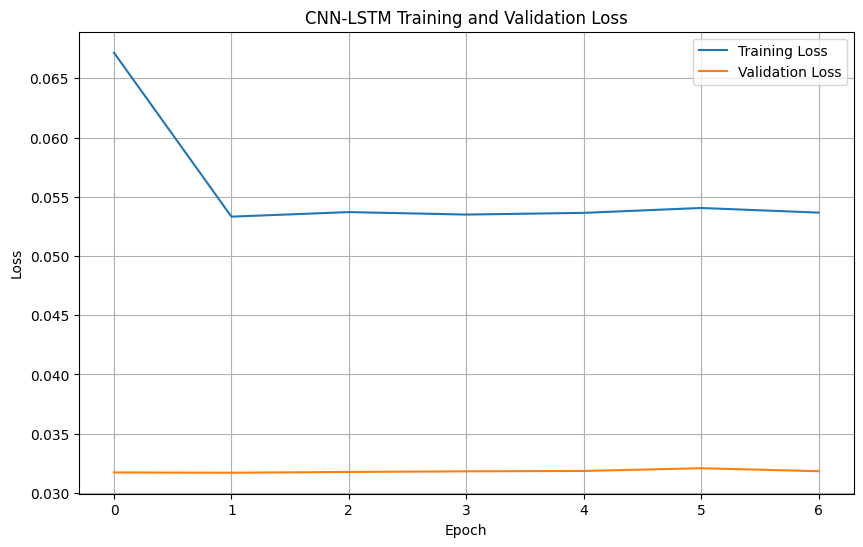

In [68]:
# Cell 31 — Plot Training and Validation Loss

plt.figure(figsize=(10, 6))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN-LSTM Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

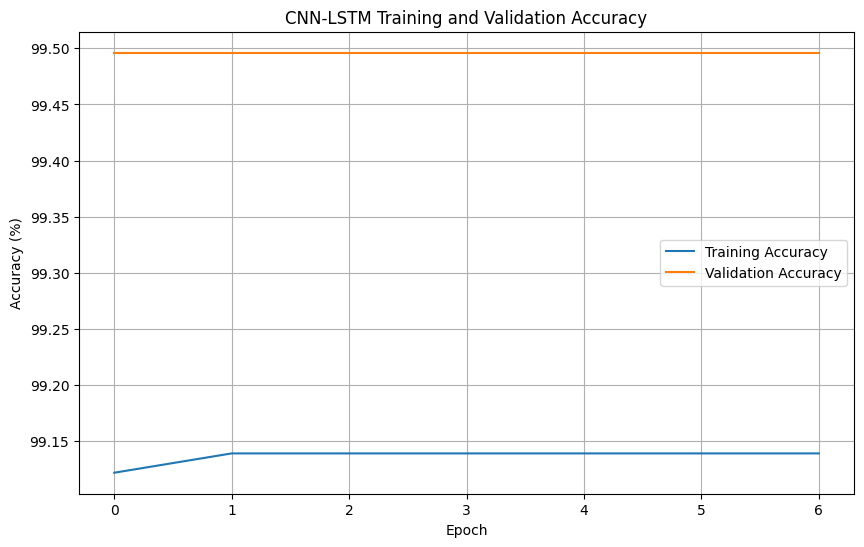

In [69]:
# Cell 32 — Plot Training and Validation Accuracy

plt.figure(figsize=(10, 6))

plt.plot(
    np.array(train_accuracies) * 100,
    label="Training Accuracy"
)

plt.plot(
    np.array(val_accuracies) * 100,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN-LSTM Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()

In [70]:
# Cell 33 — Final Test Evaluation

test_loss, test_accuracy, test_labels, test_probabilities = evaluate_model(
    model,
    test_loader,
    criterion,
    device
)

test_predictions = (
    test_probabilities >= 0.5
).astype(int)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

Test Loss: 0.0754
Test Accuracy: 98.68%


In [71]:
# Cell 34 — Calculate Classification Metrics

accuracy = accuracy_score(
    test_labels,
    test_predictions
)

precision = precision_score(
    test_labels,
    test_predictions,
    zero_division=0
)

recall = recall_score(
    test_labels,
    test_predictions,
    zero_division=0
)

f1 = f1_score(
    test_labels,
    test_predictions,
    zero_division=0
)

roc_auc = roc_auc_score(
    test_labels,
    test_probabilities
)

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall (Sensitivity)",
        "F1-Score",
        "ROC-AUC"
    ],

    "CNN-LSTM": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

results["CNN-LSTM"] = (
    results["CNN-LSTM"] * 100
)

display(results)

,Metric,CNN-LSTM
0,Accuracy,98.680619
1,Precision,98.680619
2,Recall (Sensitivity),100.000000
3,F1-Score,99.335929
4,ROC-AUC,50.546096


In [72]:
# Cell 35 — Classification Report

print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=["Normal", "Abnormal"],
        digits=4
    )
)

              precision    recall  f1-score   support

      Normal     0.0000    0.0000    0.0000        29
    Abnormal     0.9868    1.0000    0.9934      2169

    accuracy                         0.9868      2198
   macro avg     0.4934    0.5000    0.4967      2198
weighted avg     0.9738    0.9868    0.9803      2198



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Confusion Matrix:
[[   0   29]
 [   0 2169]]


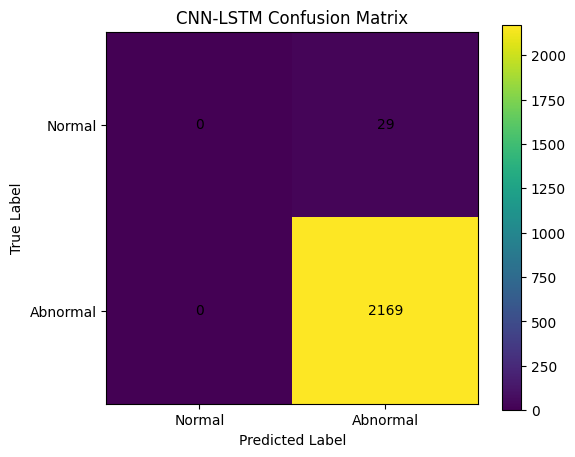

In [73]:
# Cell 36 — Confusion Matrix

cm = confusion_matrix(
    test_labels,
    test_predictions
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("CNN-LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    [0, 1],
    ["Normal", "Abnormal"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Abnormal"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

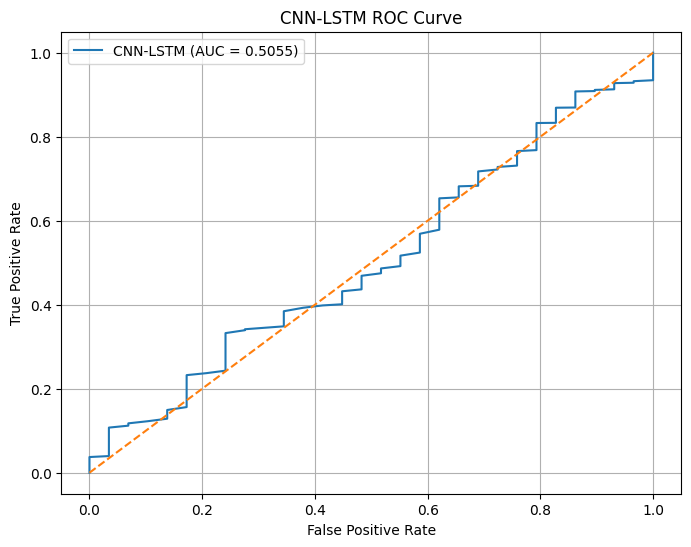

In [74]:
# Cell 37 — ROC Curve

fpr, tpr, thresholds = roc_curve(
    test_labels,
    test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"CNN-LSTM (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("CNN-LSTM ROC Curve")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Cell 38 — Final CNN-LSTM Summary

print("=" * 50)
print("CNN-LSTM FINAL RESULTS")
print("=" * 50)

print(f"Best Epoch       : {best_epoch}")
print(f"Training Time    : {total_training_time:.2f} seconds")
print(f"Test Loss        : {test_loss:.4f}")
print(f"Accuracy         : {accuracy*100:.2f}%")
print(f"Precision        : {precision*100:.2f}%")
print(f"Recall           : {recall*100:.2f}%")
print(f"F1-Score         : {f1*100:.2f}%")
print(f"ROC-AUC          : {roc_auc:.4f}")
print(f"Parameters       : {total_params:,}")